# Stage 08 — Check hosted request reliability

**Current protocol: notation-normalized final answers.** The strict-output version is preserved under `01_strict_output/`, with its exact notebook archived. Medium effort hit length limits on several development cases. Low effort also returned a SAN-like answer whose check annotation did not match the position. Canonical SAN normalization is now supported, while that noncanonical annotation remains a format failure.

This version accepts only one whole, unambiguous legal UCI or canonical SAN move, and converts it to UCI before scoring. It neither extracts guesses from commentary nor supplies an engine/solution. All original development responses are rescored offline; none are rerun for better answers. Medium is preferred if it passes the same reliability gate; low is the predeclared fallback. Capability requests already completed are also reused.

Reused failures and synthetic mirrored fixtures are development checks, not fresh accuracy observations. The selected protocol must pass the audited gate before stage 09. Sources: [Groq rate limits](https://console.groq.com/docs/rate-limits), [reasoning](https://console.groq.com/docs/reasoning), [structured outputs](https://console.groq.com/docs/structured-outputs).


## Setup and frozen protocol

In [1]:

from pathlib import Path
from datetime import datetime,timezone
from collections import Counter
import json,hashlib,re,time,uuid,math
import requests,chess,nbformat
import pandas as pd
import numpy as np
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'experiments/stage_index.json').exists())
STAGE_NAME='08_hosted_reliability'
CFG_DIR=ROOT/'experiments'/STAGE_NAME
CONFIG=json.loads((CFG_DIR/'config.json').read_text())
PROMPT=(CFG_DIR/'prompt.txt').read_text()
OUT=ROOT/'data/experiments'/STAGE_NAME;OUT.mkdir(parents=True,exist_ok=True)
def sha(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()
def save(name,value):
    (OUT/name).write_text(json.dumps(value,indent=2,ensure_ascii=False)+'\n',encoding='utf-8')
def records(name):
    p=OUT/name
    return [json.loads(s) for s in p.read_text(encoding='utf-8').splitlines() if s.strip()] if p.exists() else []
def append(name,row):
    with (OUT/name).open('a',encoding='utf-8') as f:f.write(json.dumps(row,ensure_ascii=False)+'\n');f.flush()
def freeze():
    n=nbformat.read(ROOT/'notebooks'/'08_check_hosted_reliability.ipynb',as_version=4)
    manifest={'config':CONFIG,'prompt_sha256':sha(CFG_DIR/'prompt.txt'),'notebook_code_sha256':hashlib.sha256('\n\n'.join(c.source for c in n.cells if c.cell_type=='code').encode()).hexdigest()}
    if (OUT/'manifest.json').exists():assert manifest==json.loads((OUT/'manifest.json').read_text()),'Protocol changed. Create a new version.'
    else:save('manifest.json',manifest)
freeze()
session=None
def connect():
    global session
    key=(ROOT/'api_key.txt').read_text(encoding='utf-8-sig').strip()
    assert key.startswith('gsk_'), 'Expected a locally saved Groq key'
    session=requests.Session();session.headers['Authorization']='Bearer '+key
    del key
    r=session.get(CONFIG['base_url']+'/models',timeout=30)
    if not r.ok:raise RuntimeError(f'Groq model access failed: HTTP {r.status_code}')
    assert CONFIG['model'] in {m['id'] for m in r.json()['data']}
    save('provider_models.json',r.json())
def piece_list(board):
    return '\n'.join(('White' if color else 'Black')+' pieces: '+', '.join(
        f'{chess.piece_name(p.piece_type)} {chess.square_name(s)}' for s,p in sorted(board.piece_map().items()) if p.color==color)
        for color in [chess.WHITE,chess.BLACK])
def body_for(board,task,effort):
    choices=sorted(m.uci() for m in board.legal_moves)
    prompt=PROMPT.format(side='White' if board.turn else 'Black',fen=board.fen(),pieces=piece_list(board),choices=', '.join(choices))
    if task=='side':prompt=f'Which side moves next in this FEN? {board.fen()}\n'+piece_list(board)+'\nReturn only white or black in the final answer.'
    elif task=='mate':prompt=prompt.replace('Choose the best next move','Choose a move that delivers checkmate immediately')
    elif task=='legal':prompt=prompt.replace('Choose the best next move','Choose any legal next move')
    return {'model':CONFIG['model'],'temperature':CONFIG['temperature'],'seed':CONFIG['seed'],
            'reasoning_effort':effort,'max_completion_tokens':CONFIG['max_completion_tokens'],
            'messages':[{'role':'user','content':prompt}]}
def score(board,task,response,expected=None):
    choice=response['choices'][0]
    if choice.get('finish_reason')=='length':return 'generation_limit',None,False
    if choice.get('finish_reason')!='stop':return 'nonstop_termination',None,False
    answer=choice.get('message',{}).get('content')
    if not isinstance(answer,str):return 'unparseable',None,False
    answer=answer.strip()
    if task=='side':
        if answer not in ['white','black']:return 'unparseable',answer,False
        return ('success' if answer==('white' if board.turn else 'black') else 'incorrect_side'),answer,True
    if re.fullmatch('[a-h][1-8][a-h][1-8][qrbn]?',answer):
        move=chess.Move.from_uci(answer)
        if move not in board.legal_moves:return 'illegal_move',answer,False
    else:
        try:
            move=board.parse_san(answer)
            if move not in board.legal_moves:return 'illegal_move',answer,False
            canonical=board.san(move)
            normalized=answer.replace('0-0-0','O-O-O').replace('0-0','O-O')
            if normalized not in {canonical,canonical.rstrip('+#')}:return 'unparseable',answer,False
        except ValueError:return 'unparseable',answer,False
    answer=move.uci()
    if task=='mate':
        copy=board.copy();copy.push(move)
        correct=copy.is_checkmate()
    else:correct=task=='legal' or answer==expected
    return ('success' if correct else 'legal_incorrect'),answer,True
def seconds(value):
    try:return float(value)
    except (ValueError,TypeError):
        pairs=re.findall(r'([0-9.]+)(ms|s|m|h)',str(value))
        if pairs:return sum(float(n)*{'ms':.001,'s':1,'m':60,'h':3600}[unit] for n,unit in pairs)
        try:return max(0,(datetime.strptime(value,'%a, %d %b %Y %H:%M:%S GMT').replace(tzinfo=timezone.utc)-datetime.now(timezone.utc)).total_seconds())
        except (ValueError,TypeError):return None
def pacing_wait(body):
    previous=records('requests.jsonl')
    if not previous:return 0
    row=previous[-1];headers=row.get('rate_limits',{})
    elapsed=max(0,time.time()-row.get('finished_epoch',0))
    # Conservative request reservation includes prompt estimate and the full output budget.
    need=body['max_completion_tokens']+math.ceil(sum(len(m['content']) for m in body['messages'])/2.5)+128
    limit=float(headers.get('x-ratelimit-limit-tokens',8000))
    if need>limit:raise RuntimeError('Request reservation exceeds token/minute allowance; change protocol version before collection.')
    remaining=float(headers.get('x-ratelimit-remaining-tokens',-1))
    reset=seconds(headers.get('x-ratelimit-reset-tokens'))
    if remaining<need:return max(0,(reset if reset is not None else 60)-elapsed+2)
    return max(0,2-elapsed)
def latest():return {r['case_id']:r for r in records('outcomes.jsonl')}
def run_case(case_id,puzzle_id,board,task,effort,expected=None):
    previous=latest().get(case_id)
    if previous and previous['status']!='deferred_quota':return previous
    body=body_for(board,task,effort);trial=str(uuid.uuid4());started=time.perf_counter()
    response=None;state='provider_error';last_http=None
    for retry in range(5):
        last_http=None
        wait=pacing_wait(body)
        if wait>120:state='deferred_quota';break
        if wait>0:
            print(case_id,'waiting',round(wait,1),'seconds for token capacity',flush=True);time.sleep(wait)
        log={'trial_id':trial,'case_id':case_id,'puzzle_id':puzzle_id,'task':task,'effort':effort,'retry':retry,
             'timestamp_utc':datetime.now(timezone.utc).isoformat(),'request':body}
        server_wait=None
        try:
            r=session.post(CONFIG['base_url']+'/chat/completions',json=body,timeout=(15,240))
            last_http=r.status_code;log['http_status']=r.status_code
            log['rate_limits']={k.lower():v for k,v in r.headers.items() if k.lower().startswith(('x-ratelimit','retry-after'))}
            if r.ok:
                value=r.json()
                assert isinstance(value.get('choices'),list) and value['choices']
                response=value;log['response']=value;state='completed'
            else:
                try:log['provider_error']=r.json().get('error',{})
                except ValueError:log['provider_error']={'code':'non_json_error'}
                if r.status_code==429:
                    server_wait=seconds(r.headers.get('retry-after'))
                    # Do not truncate a long Retry-After and burn retries against a daily limit.
                    if server_wait is None:server_wait=seconds(r.headers.get('x-ratelimit-reset-tokens')) or 60
                    state='deferred_quota'
        except (requests.RequestException,ValueError,AssertionError) as error:
            log['error_type']=type(error).__name__;state='transport_error'
        log['finished_epoch']=time.time();append('requests.jsonl',log)
        if response is not None:break
        if last_http==429:
            if server_wait>120:break
            print(case_id,'server requested retry after',round(server_wait,1),'seconds',flush=True)
            time.sleep(server_wait+2)
        elif last_http in [500,502,503,504,None]:time.sleep(min(30,5*2**retry))
        else:break
    category,answer,usable=score(board,task,response,expected) if response is not None else (state,None,False)
    row={'case_id':case_id,'trial_id':trial,'puzzle_id':puzzle_id,'task':task,'effort':effort,'status':state,
         'failure_type':category,'answer':answer,'usable_answer':bool(usable),
         'success':int(category=='success') if response is not None else None,
         'elapsed_seconds':round(time.perf_counter()-started,3),'http_status':last_http,
         'finish_reason':response['choices'][0].get('finish_reason') if response else None,
         'completion_tokens':response.get('usage',{}).get('completion_tokens') if response else None}
    append('outcomes.jsonl',row);print(case_id,category,row['elapsed_seconds'],'seconds',flush=True)
    return row

# Verify old experiment bytes after relocation; stage-08 work must not alter them.
protected={p.relative_to(ROOT).as_posix():sha(p) for n in range(3,8)
           for parent in [(ROOT/'data/experiments'),(ROOT/'data/analysis')]
           for directory in parent.glob(f'{n:02d}_*') for p in directory.rglob('*') if p.is_file()}
protected.update({p.relative_to(ROOT).as_posix():sha(p) for p in (OUT/'01_strict_output').rglob('*') if p.is_file()})
if (OUT/'protected_files.json').exists():assert protected==json.loads((OUT/'protected_files.json').read_text())
else:save('protected_files.json',protected)
connect()
print('Stage 08 connected; no credentials are printed or saved.')


Stage 08 connected; no credentials are printed or saved.


## Development examples and scoring checks

In [2]:

OLD=ROOT/'data/experiments/07_hosted_first_move'
old_logs=[json.loads(s) for s in (OLD/'requests.jsonl').read_text().splitlines()]
failed=sorted({r['puzzle_id'] for r in old_logs if r.get('http_status')==400 and r.get('provider_error',{}).get('code')=='json_validate_failed' and r['stage']=='evaluation'})
assert len(failed)==8
development=pd.read_csv(OLD/'evaluation_puzzles.csv',dtype={'puzzle_id':str})
development=development.loc[development.puzzle_id.isin(failed)].sort_values('puzzle_id')
assert len(development)==8
development.to_csv(OUT/'development_puzzles.csv',index=False)
source_hashes={'stage07_sample_sha256':sha(OLD/'evaluation_puzzles.csv'),'failed_ids':failed}
if (OUT/'selection.json').exists():assert source_hashes==json.loads((OUT/'selection.json').read_text())
else:save('selection.json',source_hashes)
# Fixture verification and scorer checks use chess rules only, not a solving engine.
start=chess.Board();after=start.copy();after.push_uci('e2e4')
mate=chess.Board('7k/8/5KQ1/8/8/8/8/8 w - - 0 1');mirror=mate.transform(chess.flip_horizontal)
fixtures=[('mate_a_white',mate,'mate'),('side_white',start,'side'),('legal_white',start,'legal'),
          ('side_black',after,'side'),('legal_black',after,'legal'),('mate_a_black',mate.mirror(),'mate'),
          ('mate_b_white',mirror,'mate'),('mate_b_black',mirror.mirror(),'mate')]
for name,board,task in fixtures:
    assert board.is_valid()
    if task=='mate':
        assert any((lambda b,m:(b.push(m),b.is_checkmate())[1])(board.copy(),m) for m in board.legal_moves)
fake=lambda text,reason='stop':{'choices':[{'message':{'content':text},'finish_reason':reason}]}
assert score(mate,'mate',fake('g6g7'))[0]=='success'
assert score(start,'evaluation',fake('d2d4'),'e2e4')[0]=='legal_incorrect'
assert score(start,'legal',fake('e2e5'))[0]=='illegal_move'
assert score(start,'legal',fake('Move: e2e4'))[0]=='unparseable'
assert score(start,'legal',fake('e2e4','length'))[0]=='generation_limit'
assert score(after,'side',fake('black'))[0]=='success'
print('Eight reused development cases selected; scorer and fixture checks passed.')

# New parser, unchanged prompts: legal SAN normalization is whole-answer only.
assert score(mate,'mate',fake('Qg7#'))[0]=='success'
assert score(mate,'mate',fake('Qg7'))[0]=='success'
assert score(start,'legal',fake('I choose e4'))[0]=='unparseable'
assert score(start,'legal',fake('e4'))[1]=='e2e4'
assert score(start,'legal',fake('e2e4'))[1]=='e2e4'
if not (OUT/'imported_responses.json').exists():
    source=OUT/'01_strict_output'
    old_requests=[json.loads(s) for s in (source/'requests.jsonl').read_text().splitlines()]
    old_outcomes=[json.loads(s) for s in (source/'outcomes.jsonl').read_text().splitlines()]
    by_trial={r['trial_id']:r for r in old_requests if 'response' in r}
    boards={r.puzzle_id:(chess.Board(r.solver_fen),'evaluation',r.official_first_move) for r in development.itertuples(index=False)}
    boards.update({name:(board,task,None) for name,board,task in fixtures})
    assert not records('requests.jsonl') and not records('outcomes.jsonl')
    for log in old_requests:append('requests.jsonl',log)
    imported=0
    for result in old_outcomes:
        if result['status']!='completed':continue
        board,task,expected=boards[result['puzzle_id']];raw=by_trial[result['trial_id']]
        assert raw['request']==body_for(board,task,result['effort'])
        category,answer,usable=score(board,task,raw['response'],expected)
        row={**result,'original_failure_type':result['failure_type'],'failure_type':category,
             'answer':answer,'usable_answer':bool(usable),'success':int(category=='success'),
             'provenance':'Offline rescore of strict-output raw response; no new inference'}
        append('outcomes.jsonl',row);imported+=1
    save('imported_responses.json',{'source':'01_strict_output','completed_responses':imported,
                                  'source_manifest_sha256':sha(source/'manifest.json'),'note':'All original strict-output records preserved; no correctness-based reruns.'})
print('Offline notation normalization complete; only missing capability requests may need inference.')


Eight reused development cases selected; scorer and fixture checks passed.
Offline notation normalization complete; only missing capability requests may need inference.


## Reliability test and capability gate

In [3]:

diagnostics=[];selected=None;paused=False;arm_summary=[]
for effort in CONFIG['arms']:
    arm=[]
    for row in development.itertuples(index=False):
        result=run_case(f'development:{effort}:{row.puzzle_id}',row.puzzle_id,chess.Board(row.solver_fen),'evaluation',effort,row.official_first_move)
        arm.append(result);diagnostics.append(result)
        if result['status']=='deferred_quota':paused=True;break
    passed=len(arm)==8 and sum(r['usable_answer'] for r in arm)>=7 and all(r['status']=='completed' for r in arm)
    arm_summary.append({'effort':effort,'run':len(arm),'usable':sum(r['usable_answer'] for r in arm),'correct':sum(r['success']==1 for r in arm),'passed':bool(passed)})
    if paused:break
    if passed:selected=effort;break
diagnostic_frame=pd.DataFrame(diagnostics);diagnostic_frame.to_csv(OUT/'development_results.csv',index=False)
cap=[]
if selected and not paused:
    for name,board,task in fixtures:
        result=run_case(f'capability:{selected}:{name}',name,board,task,selected)
        cap.append(result)
        if result['status']=='deferred_quota':paused=True;break
capability=pd.DataFrame(cap)
capability.to_csv(OUT/'capability_results.csv',index=False)
counts=Counter(r['task'] for r in cap if r['success']==1)
ready=bool(selected and len(cap)==8 and all(r['status']=='completed' and r['usable_answer'] for r in cap)
           and counts['side']==2 and counts['legal']==2 and counts['mate']>=2 and not paused)
gate={'ready_for_fresh_collection':ready,'selected_effort':selected,'development_arms':arm_summary,
      'capability_successes':dict(counts),'capability_run':len(cap),'paused_for_quota':paused,
      'decision':'Proceed to stage 09 with frozen selected settings' if ready else 'Resume stage 08 after quota reset' if paused else 'Keep fresh collection blocked; investigate the documented failure types in a new version'}
save('readiness_gate.json',gate)
display(diagnostic_frame);display(capability);print(json.dumps(gate,indent=2))


,case_id,trial_id,puzzle_id,task,effort,status,failure_type,answer,usable_answer,success,elapsed_seconds,http_status,finish_reason,completion_tokens,original_failure_type,provenance
0,development:medium:2EtHZ,ea1739a1-4a9d-49bc-b81d-78b3c7060726,2EtHZ,evaluation,medium,completed,generation_limit,NaN,False,0,12.939,200,length,6000,generation_limit,Offline rescore of strict-output raw response;...
1,development:medium:8fdAd,2e5577f2-6446-4b8d-b6e4-fc781eb411e2,8fdAd,evaluation,medium,completed,generation_limit,NaN,False,0,15.049,200,length,6000,generation_limit,Offline rescore of strict-output raw response;...
2,development:medium:9xMyY,63d8a762-e82d-4fc3-9e83-989e279d7c68,9xMyY,evaluation,medium,completed,generation_limit,NaN,False,0,61.455,200,length,6000,generation_limit,Offline rescore of strict-output raw response;...
3,development:medium:EkJSz,72250a0a-00f7-45f4-adc9-d66f0ad9f964,EkJSz,evaluation,medium,completed,legal_incorrect,a5c3,True,0,60.775,200,stop,5400,legal_incorrect,Offline rescore of strict-output raw response;...
4,development:medium:F8Qrd,b82d1a76-2dd8-4052-9a44-1bb221681a8e,F8Qrd,evaluation,medium,completed,generation_limit,NaN,False,0,63.930,200,length,6000,generation_limit,Offline rescore of strict-output raw response;...
5,development:medium:fAuSn,73301e32-70d8-4ce4-be6f-6be1858dba93,fAuSn,evaluation,medium,completed,success,g2f1,True,1,58.041,200,stop,3451,success,Offline rescore of strict-output raw response;...
6,development:medium:q9hWQ,c5a5f91c-519f-4085-9c33-cb66ff1de006,q9hWQ,evaluation,medium,completed,legal_incorrect,g7d7,True,0,32.743,200,stop,3365,legal_incorrect,Offline rescore of strict-output raw response;...
7,development:medium:vJqtP,5023c035-42f5-4c6d-96ca-bb44b051b220,vJqtP,evaluation,medium,completed,generation_limit,NaN,False,0,15.021,200,length,6000,generation_limit,Offline rescore of strict-output raw response;...
8,development:low:2EtHZ,abc498d6-0663-48ff-9053-fdd3e07ace2b,2EtHZ,evaluation,low,completed,unparseable,Rxe8+,False,0,32.315,200,stop,1372,unparseable,Offline rescore of strict-output raw response;...
9,development:low:8fdAd,3d41ed64-5e1b-494f-884b-fd55c7d5c439,8fdAd,evaluation,low,completed,success,f5e7,True,1,39.931,200,stop,1959,success,Offline rescore of strict-output raw response;...


,case_id,trial_id,puzzle_id,task,effort,status,failure_type,answer,usable_answer,success,elapsed_seconds,http_status,finish_reason,completion_tokens,original_failure_type,provenance
0,capability:low:mate_a_white,68ebd085-3b55-40b1-8310-8053d98966cf,mate_a_white,mate,low,completed,success,g6g7,True,1,22.796,200,stop,940,success,Offline rescore of strict-output raw response;...
1,capability:low:side_white,03aff9be-0fcb-491f-9668-e23a657248a7,side_white,side,low,completed,success,white,True,1,20.074,200,stop,25,success,Offline rescore of strict-output raw response;...
2,capability:low:legal_white,5fc2a320-c94f-4dbb-b109-1d54f79e7bce,legal_white,legal,low,completed,success,e2e4,True,1,2.415,200,stop,30,success,Offline rescore of strict-output raw response;...
3,capability:low:side_black,4d89fccb-24d9-4cb5-8bd7-914ea7c632ff,side_black,side,low,completed,success,black,True,1,2.558,200,stop,85,success,Offline rescore of strict-output raw response;...
4,capability:low:legal_black,29980689-9f0e-4eae-8c55-774a8d63a3f2,legal_black,legal,low,completed,success,e7e5,True,1,2.554,200,stop,71,success,Offline rescore of strict-output raw response;...
5,capability:low:mate_a_black,b20e5e14-74c0-4f3a-8af8-de4a22778461,mate_a_black,mate,low,completed,success,g3g2,True,1,3.858,200,stop,704,success,Offline rescore of strict-output raw response;...
6,capability:low:mate_b_white,50a74fbd-c0e7-4d83-9080-3dd0802674f1,mate_b_white,mate,low,completed,success,b6b7,True,1,5.614,200,stop,1568,success,Offline rescore of strict-output raw response;...
7,capability:low:mate_b_black,24a26c76-5777-4459-8208-13be39384dfd,mate_b_black,mate,low,completed,success,b3b2,True,1,4.607,200,stop,1079,success,Offline rescore of strict-output raw response;...


{
  "ready_for_fresh_collection": true,
  "selected_effort": "low",
  "development_arms": [
    {
      "effort": "medium",
      "run": 8,
      "usable": 3,
      "correct": 1,
      "passed": false
    },
    {
      "effort": "low",
      "run": 8,
      "usable": 7,
      "correct": 1,
      "passed": true
    }
  ],
  "capability_successes": {
    "mate": 4,
    "side": 2,
    "legal": 2
  },
  "capability_run": 8,
  "paused_for_quota": false,
  "decision": "Proceed to stage 09 with frozen selected settings"
}


## Audit and development figure

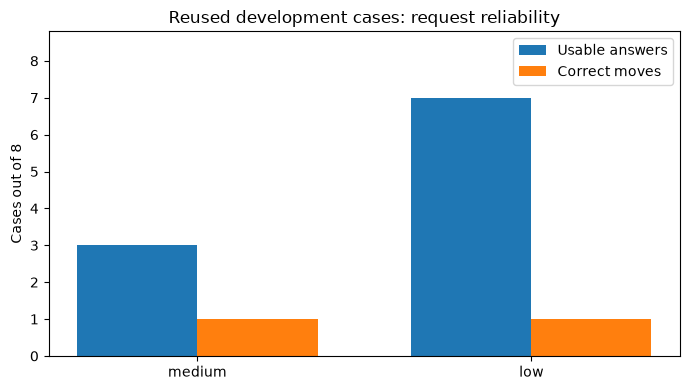

{
  "gate": {
    "ready_for_fresh_collection": true,
    "selected_effort": "low",
    "development_arms": [
      {
        "effort": "medium",
        "run": 8,
        "usable": 3,
        "correct": 1,
        "passed": false
      },
      {
        "effort": "low",
        "run": 8,
        "usable": 7,
        "correct": 1,
        "passed": true
      }
    ],
    "capability_successes": {
      "mate": 4,
      "side": 2,
      "legal": 2
    },
    "capability_run": 8,
    "paused_for_quota": false,
    "decision": "Proceed to stage 09 with frozen selected settings"
  },
  "audit": {
    "completed_responses_verified": 24,
    "historical_files_unchanged": 92,
    "passed": true
  },
  "failure_types": {
    "generation_limit": 5,
    "legal_incorrect": 8,
    "success": 10,
    "unparseable": 1
  },
  "interpretation": "Development reuse and synthetic correlated fixtures are not fresh research accuracy."
}


In [4]:

responses={r['trial_id']:r for r in records('requests.jsonl') if 'response' in r}
boards={r.puzzle_id:(chess.Board(r.solver_fen),'evaluation',r.official_first_move) for r in development.itertuples(index=False)}
boards.update({name:(board,task,None) for name,board,task in fixtures})
verified=0
for result in latest().values():
    if result['status']!='completed':continue
    board,task,expected=boards[result['puzzle_id']];log=responses[result['trial_id']]
    assert log['request']==body_for(board,task,result['effort'])
    category,answer,usable=score(board,task,log['response'],expected)
    assert result['failure_type']==category and result['answer']==answer and result['success']==int(category=='success') and result['usable_answer']==usable
    verified+=1
assert all(sha(ROOT/path)==digest for path,digest in protected.items())
audit={'completed_responses_verified':verified,'historical_files_unchanged':len(protected),'passed':True}
save('audit.json',audit)
summary={'gate':gate,'audit':audit,'failure_types':dict(Counter(r['failure_type'] for r in latest().values())),
         'interpretation':'Development reuse and synthetic correlated fixtures are not fresh research accuracy.'}
save('summary.json',summary)
import matplotlib.pyplot as plt
figdir=ROOT/'figures/08_hosted_reliability';figdir.mkdir(parents=True,exist_ok=True)
if arm_summary:
    frame=pd.DataFrame(arm_summary)
    fig,ax=plt.subplots(figsize=(7,4));x=np.arange(len(frame));ax.bar(x-.18,frame.usable,width=.36,label='Usable answers');ax.bar(x+.18,frame.correct,width=.36,label='Correct moves')
    ax.set(xticks=x,xticklabels=frame.effort,ylabel='Cases out of 8',ylim=(0,8.8),title='Reused development cases: request reliability')
    ax.legend();fig.tight_layout();fig.savefig(figdir/'development_reliability.png',dpi=160);plt.show()
session.close()
print(json.dumps(summary,indent=2))
